<a href="https://colab.research.google.com/github/Sindhuja-R-23/MyoVoice/blob/main/notebooks/MyoVoice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Selected device:", device)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cpu
CUDA available: False
Selected device: cpu


In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not active yet. Check the runtime setting.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/MyoVoice")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

test_file = PROJECT_DIR / "setup_test.txt"
test_file.write_text("MyoVoice workspace is ready!")

print("Project folder:", PROJECT_DIR)
print("Folder created:", PROJECT_DIR.exists())
print("Write test:", test_file.read_text())

Project folder: /content/MyoVoice
Folder created: True
Write test: MyoVoice workspace is ready!


In [3]:
%cd /content/MyoVoice

!git clone https://github.com/PortAISociety/silent_speech_asr.git

/content/MyoVoice
Cloning into 'silent_speech_asr'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 56 (delta 22), reused 18 (delta 18), pack-reused 18 (from 1)
Receiving objects: 100% (56/56), 45.36 KiB | 393.00 KiB/s, done.
Resolving deltas: 100% (25/25), done.


In [4]:
from pathlib import Path

REPO_DIR = Path("/content/MyoVoice/silent_speech_asr")

print("Project files:\n")

for item in sorted(REPO_DIR.iterdir()):
    kind = "Folder" if item.is_dir() else "File"
    print(f"{kind:8} {item.name}")

Project files:

Folder   .git
File     LICENSE
File     README.md
File     align.py
File     asr.py
Folder   data_collection
File     data_utils.py
File     evaluate.py
File     make_vocoder_trainset.py
File     normalizers.pkl
File     read_emg.py
File     testset_largedev.json
File     testset_origdev.json
File     transduction_model.py
File     transformer.py
File     vocoder.py


In [5]:
from pathlib import Path

readme = Path("/content/MyoVoice/silent_speech_asr/README.md")

print(readme.read_text()[:12000])

# Voicing Silent Speech

This repository contains code for synthesizing speech audio from silently mouthed words captured with electromyography (EMG).
It is the official repository for the papers [Digital Voicing of Silent Speech](https://aclanthology.org/2020.emnlp-main.445.pdf) at EMNLP 2020, [An Improved Model for Voicing Silent Speech](https://aclanthology.org/2021.acl-short.23.pdf) at ACL 2021, and the dissertation [Voicing Silent Speech](https://www2.eecs.berkeley.edu/Pubs/TechRpts/2022/EECS-2022-68.pdf).
The current commit contains only the most recent model, but the versions from prior papers can be found in the commit history.
On an ASR-based open vocabulary evaluation, the latest model achieves a WER of approximately 36%.

## Data

The EMG and audio data can be downloaded from <https://doi.org/10.5281/zenodo.4064408>.  The scripts expect the data to be located in a `emg_data` subdirectory by default, but the location can be overridden with flags (see the top of `read_emg.py`)

In [6]:
import importlib.util
import torch
import sys

packages = [
    "numpy",
    "librosa",
    "soundfile",
    "scipy",
    "matplotlib",
    "absl",
    "praat_textgrids",
    "deepspeech",
]

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("\nPackage availability:")

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

Python: 3.13.15
PyTorch: 2.11.0+cu130

Package availability:
numpy: Installed
librosa: Installed
soundfile: Installed
scipy: Installed
matplotlib: Installed
absl: Installed
praat_textgrids: Not installed
deepspeech: Not installed


In [7]:
%pip install praat-textgrids

In [10]:
from importlib.metadata import packages_distributions

matches = {
    name: distributions
    for name, distributions in packages_distributions().items()
    if "praat" in name.lower() or any(
        "praat" in dist.lower() for dist in distributions
    )
}

print("Praat-related Python modules:", matches)

Praat-related Python modules: {'textgrids': ['praat-textgrids']}


In [11]:
import torch
import numpy as np
import librosa
import soundfile as sf
import scipy
import matplotlib
import textgrids

print("✅ PyTorch:", torch.__version__)
print("✅ NumPy:", np.__version__)
print("✅ Librosa:", librosa.__version__)
print("✅ SoundFile:", sf.__version__)
print("✅ SciPy:", scipy.__version__)
print("✅ Matplotlib:", matplotlib.__version__)
print("✅ TextGrids: imported successfully")
print("✅ CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("✅ GPU:", torch.cuda.get_device_name(0))

✅ PyTorch: 2.11.0+cu130
✅ NumPy: 2.1.3
✅ Librosa: 0.11.0
✅ SoundFile: 0.14.0
✅ SciPy: 1.16.3
✅ Matplotlib: 3.10.0
✅ TextGrids: imported successfully
✅ CUDA available: True
✅ GPU: Tesla T4


In [12]:
from pathlib import Path

dataset_dir = Path("/content/MyoVoice")
archive_path = dataset_dir / "emg_data.tar.gz"

print("Dataset folder:", dataset_dir)
print("Archive path:", archive_path)
print("Already downloaded:", archive_path.exists())

Dataset folder: /content/MyoVoice
Archive path: /content/MyoVoice/emg_data.tar.gz
Already downloaded: False


In [14]:
import requests

api_url = "https://zenodo.org/api/records/4064409"
response = requests.get(api_url, timeout=30)
response.raise_for_status()

metadata = response.json()

for file_info in metadata["files"]:
    print("Filename:", file_info["key"])
    print("Size (GB):", round(file_info["size"] / 1e9, 2))
    print("Download URL:", file_info["links"]["self"])
    print("Checksum:", file_info.get("checksum"))

Filename: emg_data.tar.gz
Size (GB): 3.92
Download URL: https://zenodo.org/api/records/4064409/files/emg_data.tar.gz/content
Checksum: md5:7f97d2182b896652999b1b2d0c69fd7b


In [15]:
from pathlib import Path
import subprocess

archive = Path("/content/MyoVoice/emg_data.tar.gz")
url = "https://zenodo.org/api/records/4064409/files/emg_data.tar.gz/content"

archive.parent.mkdir(parents=True, exist_ok=True)

if archive.exists() and archive.stat().st_size > 0:
    print(f"Existing partial/full file: {archive.stat().st_size:,} bytes")
else:
    print("Starting dataset download...")

result = subprocess.run([
    "wget",
    "-c",
    "--show-progress",
    "-O", str(archive),
    url
])

if result.returncode != 0:
    print("Download did not finish. Keep the partial file; we can resume it.")
else:
    print("Download command finished.")
    print("File size (GB):", round(archive.stat().st_size / 1e9, 2))

Starting dataset download...


KeyboardInterrupt: 

In [16]:
from pathlib import Path

archive = Path("/content/MyoVoice/emg_data.tar.gz")

if archive.exists():
    size_gb = archive.stat().st_size / 1e9
    print(f"Partial download size: {size_gb:.3f} GB")
    print(f"File size: {archive.stat().st_size:,} bytes")
else:
    print("No archive file exists yet.")

Partial download size: 2.640 GB
File size: 2,640,209,288 bytes


In [17]:
%cd /content/MyoVoice

!wget -c --progress=bar:force:noscroll \
  -O emg_data.tar.gz \
  "https://zenodo.org/api/records/4064409/files/emg_data.tar.gz/content"

/content/MyoVoice
--2026-10-19 11:02:31--  https://zenodo.org/api/records/4064409/files/emg_data.tar.gz/content
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.47.192, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 206 PARTIAL_CONTENT
Length: 3919507637 (3.6G), 1279298349 (1.2G) remaining [application/octet-stream]
Saving to: ‘emg_data.tar.gz’

emg_data.tar.gz     100%[+++++++++++++======>]   3.65G  3.13MB/s    in 6m 21s  

2026-10-19 11:08:52 (3.21 MB/s) - ‘emg_data.tar.gz’ saved [3919507637/3919507637]



In [18]:
import hashlib
from pathlib import Path

archive = Path("/content/MyoVoice/emg_data.tar.gz")
expected_md5 = "7f97d2182b896652999b1b2d0c69fd7b"

print("Checking dataset integrity...")

md5 = hashlib.md5()

with archive.open("rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        md5.update(chunk)

actual_md5 = md5.hexdigest()

print("File size (GB):", round(archive.stat().st_size / 1e9, 3))
print("Expected MD5:", expected_md5)
print("Actual MD5:  ", actual_md5)

if actual_md5 == expected_md5:
    print("✅ Dataset verified successfully!")
else:
    print("❌ Checksum mismatch. Do not extract yet.")

Checking dataset integrity...
File size (GB): 3.92
Expected MD5: 7f97d2182b896652999b1b2d0c69fd7b
Actual MD5:   7f97d2182b896652999b1b2d0c69fd7b
✅ Dataset verified successfully!


In [20]:
from pathlib import Path
import tarfile

archive = Path("/content/MyoVoice/emg_data.tar.gz")
project_dir = Path("/content/MyoVoice")

print("Extracting dataset... This may take several minutes.")

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path=project_dir, filter="data")

print("✅ Extraction completed!")

print("\nExtracted folders:")
for item in sorted(project_dir.iterdir()):
    if item.is_dir():
        print("-", item.name)

Extracting dataset... This may take several minutes.
✅ Extraction completed!

Extracted folders:
- emg_data
- silent_speech_asr


In [21]:
from pathlib import Path

DATA_DIR = Path("/content/MyoVoice/emg_data")

print("Dataset directory exists:", DATA_DIR.exists())
print("\nDataset subfolders:")

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        file_count = sum(1 for item in folder.rglob("*") if item.is_file())
        print(f"{folder.name}: {file_count:,} files")

print("\nTotal dataset size (GB):",
      round(sum(p.stat().st_size for p in DATA_DIR.rglob("*") if p.is_file()) / 1e9, 2))

Dataset directory exists: True

Dataset subfolders:
closed_vocab: 6,480 files
nonparallel_data: 34,165 files
silent_parallel_data: 10,940 files
voiced_parallel_data: 10,340 files

Total dataset size (GB): 6.77


In [22]:
from pathlib import Path

DATA_DIR = Path("/content/MyoVoice/emg_data")

# Find one EMG recording file
emg_files = sorted(DATA_DIR.rglob("*_emg.npy"))

print("EMG files found:", len(emg_files))

if emg_files:
    first_file = emg_files[0]
    print("\nExample EMG file:")
    print(first_file)
    print("File size (KB):", round(first_file.stat().st_size / 1024, 2))
else:
    print("No *_emg.npy files found. We'll inspect the actual filenames next.")

EMG files found: 12385

Example EMG file:
/content/MyoVoice/emg_data/closed_vocab/silent/5-19_silent/0_emg.npy
File size (KB): 166.62


In [23]:
import numpy as np
from pathlib import Path

emg_file = Path(
    "/content/MyoVoice/emg_data/closed_vocab/silent/5-19_silent/0_emg.npy"
)

emg = np.load(emg_file, allow_pickle=False)

print("File:", emg_file.name)
print("Data shape:", emg.shape)
print("Data type:", emg.dtype)
print("Minimum:", np.min(emg))
print("Maximum:", np.max(emg))
print("Mean:", np.mean(emg))
print("Standard deviation:", np.std(emg))
print("Contains NaN:", np.isnan(emg).any())
print("Contains infinity:", np.isinf(emg).any())

File: 0_emg.npy
Data shape: (2664, 8)
Data type: float64
Minimum: -75701.8203125
Maximum: -16633.7421875
Mean: -46651.98229916317
Standard deviation: 17878.086297211987
Contains NaN: False
Contains infinity: False


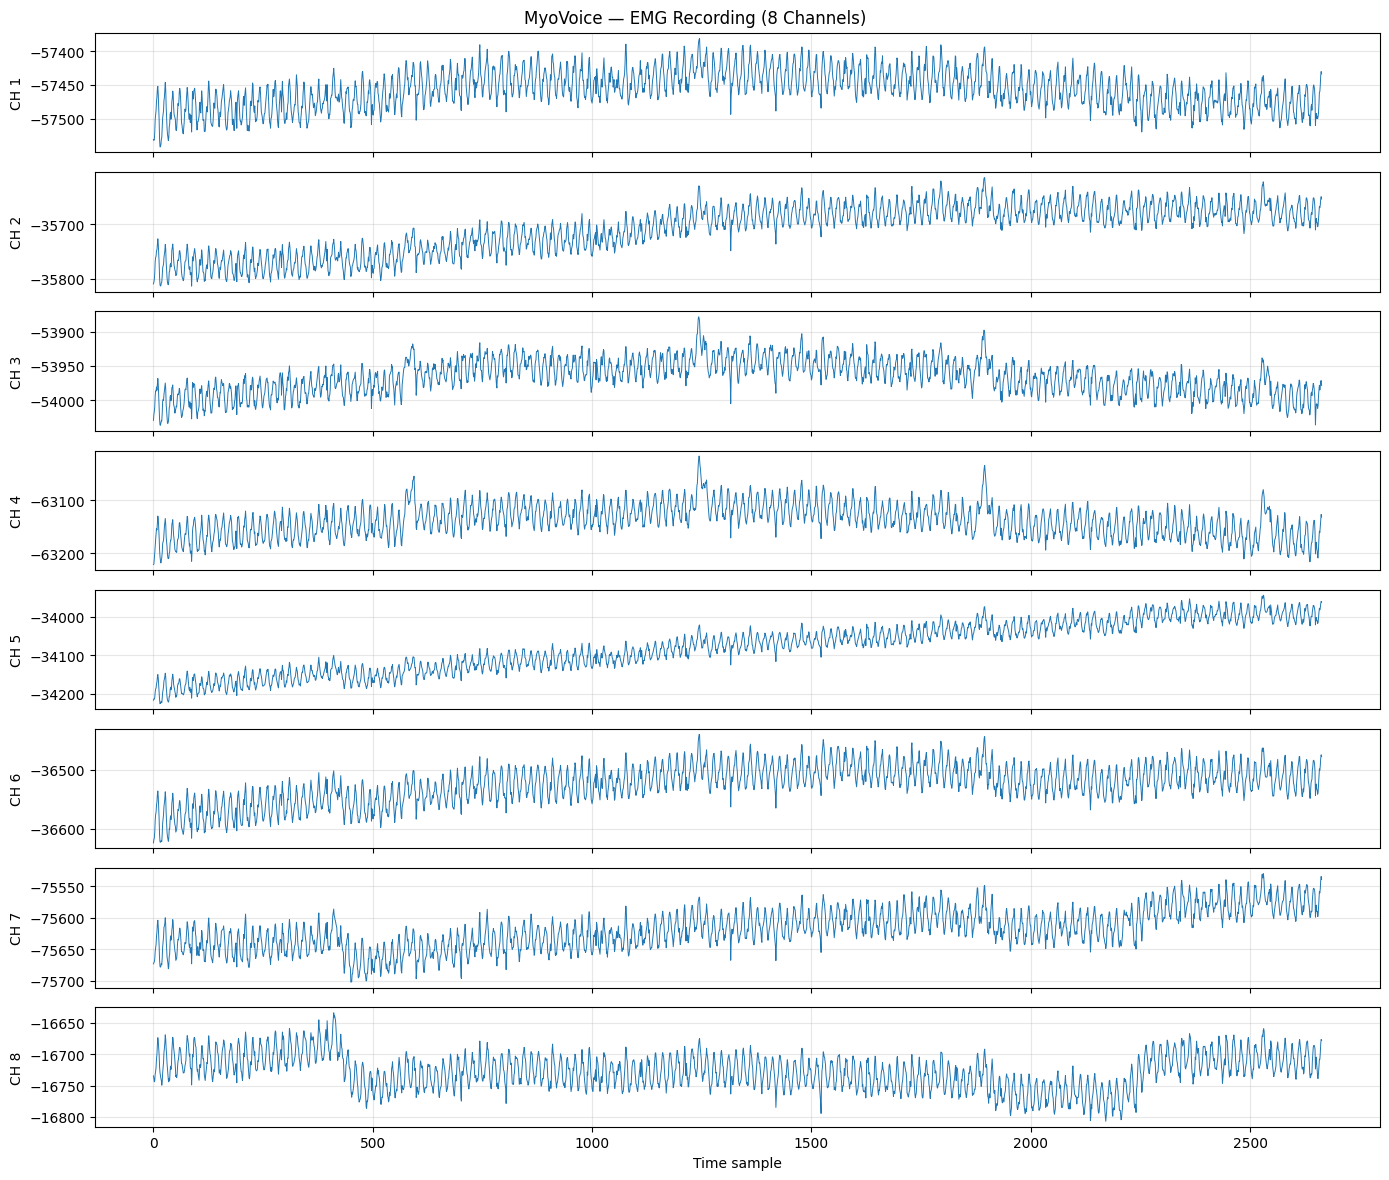

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

emg_file = Path(
    "/content/MyoVoice/emg_data/closed_vocab/silent/5-19_silent/0_emg.npy"
)
emg = np.load(emg_file, allow_pickle=False)

fig, axes = plt.subplots(8, 1, figsize=(14, 12), sharex=True)

for channel in range(8):
    axes[channel].plot(emg[:, channel], linewidth=0.7)
    axes[channel].set_ylabel(f"CH {channel + 1}")
    axes[channel].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time sample")
fig.suptitle("MyoVoice — EMG Recording (8 Channels)")
plt.tight_layout()
plt.show()

In [25]:
from pathlib import Path

repo = Path("/content/MyoVoice/silent_speech_asr")

for filename in ["read_emg.py", "data_utils.py"]:
    path = repo / filename
    print(f"\n{'=' * 20} {filename} {'=' * 20}")

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "raw_emg", "np.load", "normalize", "sample_rate",
            "sampling_rate", "emg_rate"
        ]):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)
            print(f"\n--- lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")


==================== read_emg.py ====================

--- lines 20-25 ---
20: import torch
21: 
22: from data_utils import load_audio, get_emg_features, FeatureNormalizer, phoneme_inventory, read_phonemes
23: 
24: from absl import flags
25: FLAGS = flags.FLAGS

--- lines 57-62 ---
57: def load_utterance(base_dir, index, limit_length=False, debug=False, text_align_directory=None):
58:     index = int(index)
59:     raw_emg = np.load(os.path.join(base_dir, f'{index}_emg.npy'))
60:     before = os.path.join(base_dir, f'{index-1}_emg.npy')
61:     after = os.path.join(base_dir, f'{index+1}_emg.npy')
62:     if os.path.exists(before):

--- lines 61-66 ---
61:     after = os.path.join(base_dir, f'{index+1}_emg.npy')
62:     if os.path.exists(before):
63:         raw_emg_before = np.load(before)
64:     else:
65:         raw_emg_before = np.zeros([0,raw_emg.shape[1]])
66:     if os.path.exists(after):

--- lines 63-68 ---
63:         raw_emg_before = np.load(before)
64:     else:
65:       

In [26]:
from pathlib import Path

path = Path("/content/MyoVoice/silent_speech_asr/read_emg.py")
lines = path.read_text().splitlines()

for start, end in [(1, 80)]:
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")

1: import re
2: import os
3: import numpy as np
4: import matplotlib.pyplot as plt
5: import random
6: from collections import defaultdict
7: import scipy
8: import json
9: import copy
10: import sys
11: import pickle
12: import string
13: import logging
14: from functools import lru_cache
15: from copy import copy
16: 
17: import librosa
18: import soundfile as sf
19: 
20: import torch
21: 
22: from data_utils import load_audio, get_emg_features, FeatureNormalizer, phoneme_inventory, read_phonemes
23: 
24: from absl import flags
25: FLAGS = flags.FLAGS
26: flags.DEFINE_list('remove_channels', [], 'channels to remove')
27: flags.DEFINE_list('silent_data_directories', ['./emg_data/silent_parallel_data'], 'silent data locations')
28: flags.DEFINE_list('voiced_data_directories', ['./emg_data/voiced_parallel_data','./emg_data/nonparallel_data'], 'voiced data locations')
29: flags.DEFINE_string('testset_file', 'testset_largedev.json', 'file with testset indices')
30: flags.DEFINE_string('te

Raw mean: -46651.98
Processed mean: 0.481
Processed standard deviation: 10.6175
Processed values finite: True


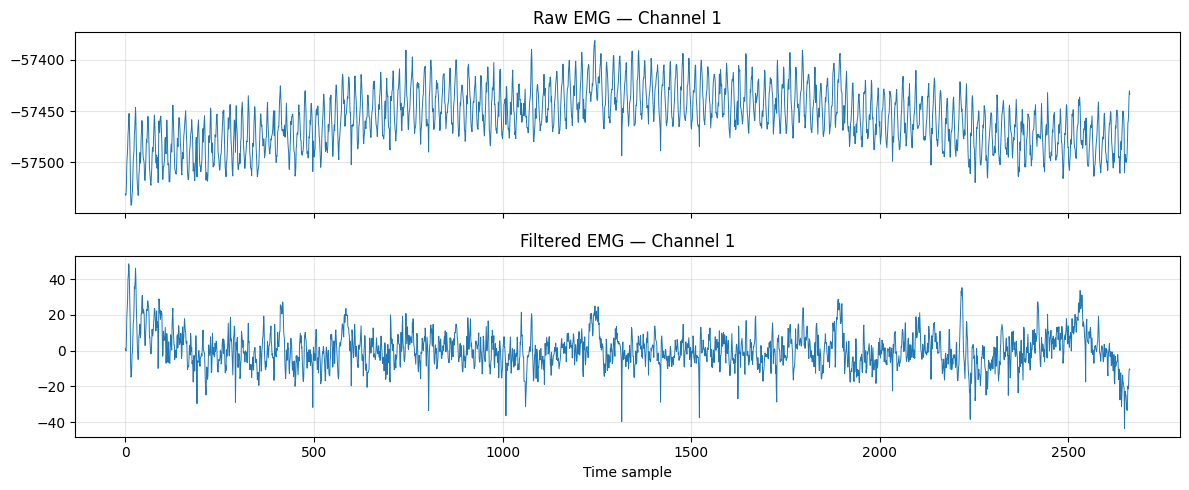

In [27]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
from pathlib import Path

# Load one original EMG recording
emg_path = Path(
    "/content/MyoVoice/emg_data/closed_vocab/silent/5-19_silent/0_emg.npy"
)
raw_emg = np.load(emg_path, allow_pickle=False)

# Original project's filtering functions
def notch(sig, freq, sample_frequency):
    b, a = signal.iirnotch(freq, 30, sample_frequency)
    return signal.filtfilt(b, a, sig)

def notch_harmonics(sig, freq, sample_frequency):
    for harmonic in range(1, 8):
        target_freq = freq * harmonic
        if target_freq < sample_frequency / 2:
            sig = notch(sig, target_freq, sample_frequency)
    return sig

def remove_drift(sig, fs):
    b, a = signal.butter(3, 2, "highpass", fs=fs)
    return signal.filtfilt(b, a, sig)

# Filter each of the 8 channels
filtered_emg = np.stack([
    remove_drift(notch_harmonics(raw_emg[:, ch].copy(), 60, 1000), 1000)
    for ch in range(raw_emg.shape[1])
], axis=1)

print("Raw mean:", round(float(raw_emg.mean()), 2))
print("Processed mean:", round(float(filtered_emg.mean()), 4))
print("Processed standard deviation:", round(float(filtered_emg.std()), 4))
print("Processed values finite:", bool(np.isfinite(filtered_emg).all()))

# Plot one channel before and after filtering
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

axes[0].plot(raw_emg[:, 0], linewidth=0.7)
axes[0].set_title("Raw EMG — Channel 1")
axes[0].grid(True, alpha=0.3)

axes[1].plot(filtered_emg[:, 0], linewidth=0.7)
axes[1].set_title("Filtered EMG — Channel 1")
axes[1].set_xlabel("Time sample")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
import numpy as np

def subsample(signal, new_freq, old_freq):
    times = np.arange(len(signal)) / old_freq
    sample_times = np.arange(0, times[-1], 1 / new_freq)
    return np.interp(sample_times, times, signal)

resampled_emg = np.stack([
    subsample(filtered_emg[:, ch], 516.79, 1000)
    for ch in range(filtered_emg.shape[1])
], axis=1)

print("Original shape:", raw_emg.shape)
print("Filtered shape:", filtered_emg.shape)
print("Resampled shape:", resampled_emg.shape)
print("New sampling rate: 516.79 Hz")
print("Duration (seconds):", round(len(resampled_emg) / 516.79, 3))
print("All values finite:", bool(np.isfinite(resampled_emg).all()))

Original shape: (2664, 8)
Filtered shape: (2664, 8)
Resampled shape: (1377, 8)
New sampling rate: 516.79 Hz
Duration (seconds): 2.665
All values finite: True


In [29]:
from pathlib import Path

path = Path("/content/MyoVoice/silent_speech_asr/read_emg.py")
lines = path.read_text().splitlines()

# Show the next section of load_utterance
for i in range(75, min(145, len(lines))):
    print(f"{i + 1}: {lines[i]}")

76:     x = apply_to_all(subsample, x, 516.79, 1000)
77:     emg = x
78: 
79:     for c in FLAGS.remove_channels:
80:         emg[:,int(c)] = 0
81:         emg_orig[:,int(c)] = 0
82: 
83:     emg_features = get_emg_features(emg)
84: 
85:     mfccs = load_audio(os.path.join(base_dir, f'{index}_audio_clean.flac'),
86:             max_frames=min(emg_features.shape[0], 800 if limit_length else float('inf')))
87: 
88:     if emg_features.shape[0] > mfccs.shape[0]:
89:         emg_features = emg_features[:mfccs.shape[0],:]
90:     assert emg_features.shape[0] == mfccs.shape[0]
91:     emg = emg[6:6+6*emg_features.shape[0],:]
92:     emg_orig = emg_orig[8:8+8*emg_features.shape[0],:]
93:     assert emg.shape[0] == emg_features.shape[0]*6
94: 
95:     with open(os.path.join(base_dir, f'{index}_info.json')) as f:
96:         info = json.load(f)
97: 
98:     sess = os.path.basename(base_dir)
99:     tg_fname = f'{text_align_directory}/{sess}/{sess}_{index}_audio.TextGrid'
100:     if os.path.exi

In [30]:
from pathlib import Path
import json

sample_dir = Path(
    "/content/MyoVoice/emg_data/closed_vocab/silent/5-19_silent"
)

for filename in [
    "0_emg.npy",
    "0_audio_clean.flac",
    "0_info.json",
]:
    path = sample_dir / filename
    print(f"{filename}: {'Found' if path.exists() else 'Missing'}")

info_path = sample_dir / "0_info.json"

if info_path.exists():
    info = json.loads(info_path.read_text())
    print("\nMetadata keys:", list(info.keys()))
    print("Text:", info.get("text"))
    print("Book:", info.get("book"))
    print("Sentence index:", info.get("sentence_index"))

0_emg.npy: Found
0_audio_clean.flac: Found
0_info.json: Found

Metadata keys: ['book', 'sentence_index', 'text', 'chunks']
Text: 
Book: 
Sentence index: -1


In [31]:
from pathlib import Path
import json

DATA_DIR = Path("/content/MyoVoice/emg_data")
found = False

for info_path in DATA_DIR.rglob("*_info.json"):
    try:
        info = json.loads(info_path.read_text())
        text = info.get("text", "").strip()
        sentence_index = info.get("sentence_index", -1)

        if text and sentence_index != -1:
            prefix = info_path.name.removesuffix("_info.json")
            emg_path = info_path.with_name(f"{prefix}_emg.npy")
            audio_path = info_path.with_name(f"{prefix}_audio_clean.flac")

            if emg_path.exists() and audio_path.exists():
                print("✅ Valid labeled sample found")
                print("EMG:", emg_path)
                print("Audio:", audio_path)
                print("Text:", text)
                print("Sentence index:", sentence_index)
                found = True
                break
    except (OSError, json.JSONDecodeError):
        continue

if not found:
    print("No valid labeled sample found in this search.")

✅ Valid labeled sample found
EMG: /content/MyoVoice/emg_data/voiced_parallel_data/5-9/219_emg.npy
Audio: /content/MyoVoice/emg_data/voiced_parallel_data/5-9/219_audio_clean.flac
Text: A violent explosion shook the air, and a spout of water, steam, mud, and shattered metal shot far up into the sky.
Sentence index: 1074


In [32]:

from pathlib import Path
import json
import numpy as np
import soundfile as sf

emg_path = Path(
    "/content/MyoVoice/emg_data/voiced_parallel_data/5-9/219_emg.npy"
)
audio_path = Path(
    "/content/MyoVoice/emg_data/voiced_parallel_data/5-9/219_audio_clean.flac"
)
info_path = emg_path.with_name("219_info.json")

# Load the EMG signal, audio, and metadata
emg = np.load(emg_path)
audio, audio_sr = sf.read(audio_path)
info = json.loads(info_path.read_text())

print("EMG shape:", emg.shape)
print("EMG data type:", emg.dtype)
print("EMG sampling rate (raw): 1000 Hz")
print("EMG duration:", round(len(emg) / 1000, 3), "seconds")
print("Audio shape:", audio.shape)
print("Audio sampling rate:", audio_sr)
print("Audio duration:", round(len(audio) / audio_sr, 3), "seconds")
print("Text label:", info.get("text", ""))
print("Contains non-finite EMG values:", not np.isfinite(emg).all())


EMG shape: (9294, 8)
EMG data type: float64
EMG sampling rate (raw): 1000 Hz
EMG duration: 9.294 seconds
Audio shape: (148640,)
Audio sampling rate: 16000
Audio duration: 9.29 seconds
Text label: A violent explosion shook the air, and a spout of water, steam, mud, and shattered metal shot far up into the sky.
Contains non-finite EMG values: False


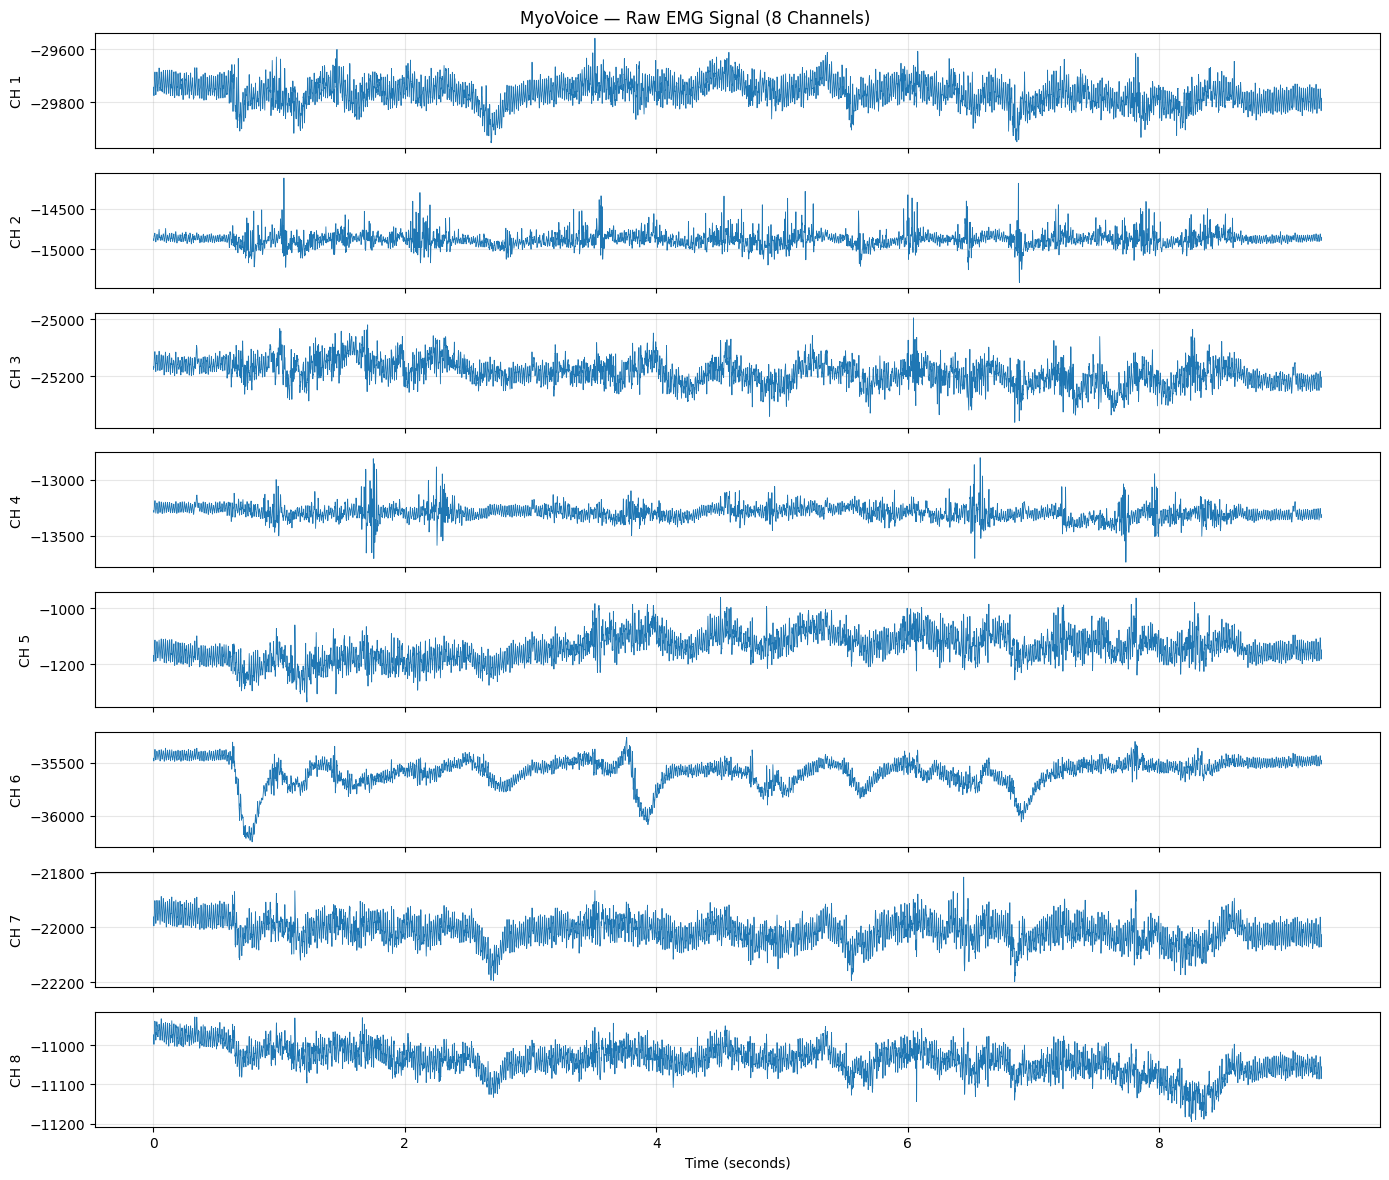

In [33]:

import matplotlib.pyplot as plt
import numpy as np

sampling_rate = 1000
time = np.arange(emg.shape[0]) / sampling_rate

fig, axes = plt.subplots(8, 1, figsize=(14, 12), sharex=True)

for channel in range(8):
    axes[channel].plot(time, emg[:, channel], linewidth=0.6)
    axes[channel].set_ylabel(f"CH {channel + 1}")
    axes[channel].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("MyoVoice — Raw EMG Signal (8 Channels)")
plt.tight_layout()
plt.show()


Original shape: (9294, 8)
Filtered shape: (9294, 8)
Filtered mean: 0.1171
Filtered standard deviation: 41.9982
Contains non-finite values: False


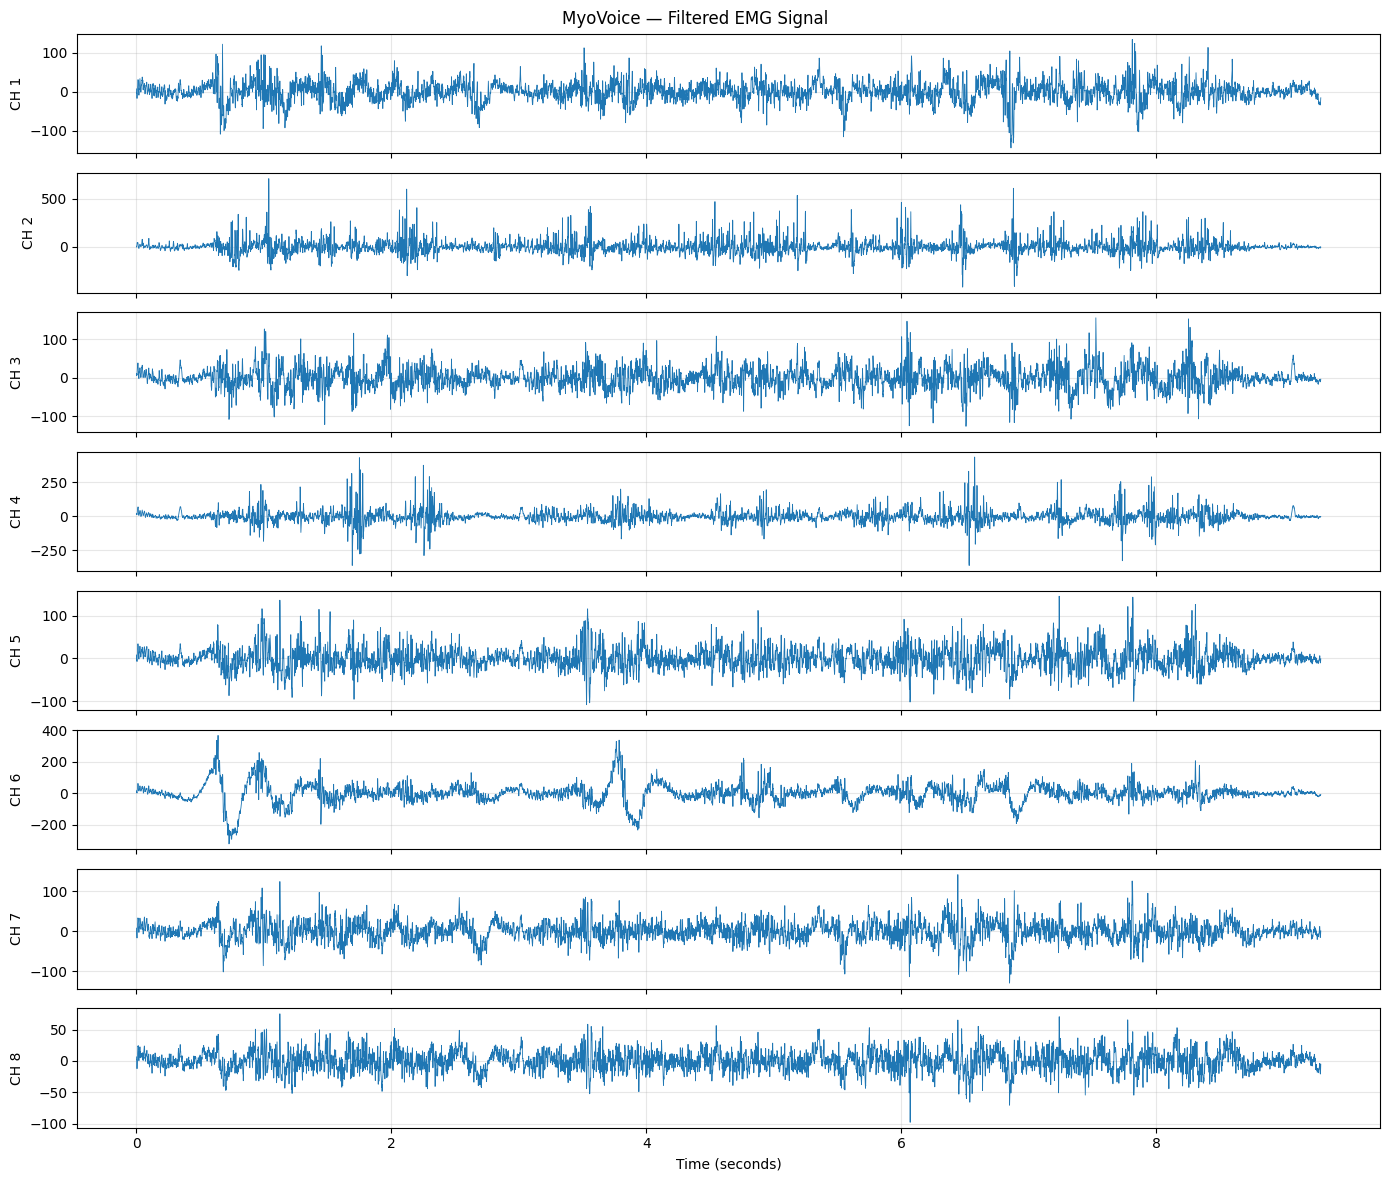

In [34]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, filtfilt

# Use the existing EMG sample
sampling_rate = 1000
filtered_emg = emg.astype(np.float64).copy()

# 1. Remove 60 Hz electrical interference and its harmonics
for frequency in range(60, sampling_rate // 2, 60):
    b, a = iirnotch(frequency, Q=30, fs=sampling_rate)
    filtered_emg = filtfilt(b, a, filtered_emg, axis=0)

# 2. Remove slow baseline drift below 2 Hz
b, a = butter(3, 2, btype="highpass", fs=sampling_rate)
filtered_emg = filtfilt(b, a, filtered_emg, axis=0)

# 3. Check the result
print("Original shape:", emg.shape)
print("Filtered shape:", filtered_emg.shape)
print("Filtered mean:", round(float(filtered_emg.mean()), 4))
print("Filtered standard deviation:", round(float(filtered_emg.std()), 4))
print("Contains non-finite values:", not np.isfinite(filtered_emg).all())

# 4. Plot the filtered channels
fig, axes = plt.subplots(8, 1, figsize=(14, 12), sharex=True)

for channel in range(8):
    axes[channel].plot(
        time, filtered_emg[:, channel], linewidth=0.6
    )
    axes[channel].set_ylabel(f"CH {channel + 1}")
    axes[channel].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("MyoVoice — Filtered EMG Signal")
plt.tight_layout()
plt.show()


In [35]:

import numpy as np
import pandas as pd

# Use 200 ms windows with 50 ms between window starts
sampling_rate = 1000
window_size = 200
step_size = 50

feature_rows = []
feature_times = []

for start in range(0, len(filtered_emg) - window_size + 1, step_size):
    window = filtered_emg[start:start + window_size, :]

    mav = np.mean(np.abs(window), axis=0)
    rms = np.sqrt(np.mean(window ** 2, axis=0))
    wl = np.sum(np.abs(np.diff(window, axis=0)), axis=0)

    feature_rows.append(np.concatenate([mav, rms, wl]))
    feature_times.append((start + window_size / 2) / sampling_rate)

feature_array = np.asarray(feature_rows)

feature_names = (
    [f"CH{i+1}_MAV" for i in range(8)]
    + [f"CH{i+1}_RMS" for i in range(8)]
    + [f"CH{i+1}_WL" for i in range(8)]
)

features_df = pd.DataFrame(feature_array, columns=feature_names)

print("Feature matrix shape:", feature_array.shape)
print("Number of windows:", len(feature_array))
print("Features per window:", feature_array.shape[1])
print("\nFirst five windows:")
print(features_df.head().round(3))
print("\nContains non-finite values:", not np.isfinite(feature_array).all())


Feature matrix shape: (182, 24)
Number of windows: 182
Features per window: 24

First five windows:
   CH1_MAV  CH2_MAV  CH3_MAV  CH4_MAV  CH5_MAV  CH6_MAV  CH7_MAV  CH8_MAV  \
0   10.378   15.443   10.718   15.275   10.549   17.245   11.119    7.261   
1    9.333   12.245    8.771    9.871    8.530   12.047    9.138    6.090   
2    8.400   13.081    7.461    7.942    6.977   10.404    7.372    5.165   
3    9.602   15.049    9.928   13.154    7.777   12.808    7.423    5.877   
4   10.011   15.994    9.985   13.461    8.459   21.380    8.316    6.491   

   CH1_RMS  CH2_RMS  ...  CH7_RMS  CH8_RMS   CH1_WL    CH2_WL   CH3_WL  \
0   13.140   21.842  ...   14.093    9.308  949.686  1285.443  749.121   
1   11.401   17.513  ...   11.812    7.830  931.914  1200.748  738.585   
2   10.435   17.861  ...    8.989    6.438  914.595  1317.229  752.864   
3   12.009   19.568  ...    9.036    7.649  886.923  1414.012  769.683   
4   12.184   19.974  ...    9.886    8.180  825.826  1441.527  713.

In [36]:

from pathlib import Path
import json

SILENT_DIR = Path("/content/MyoVoice/emg_data/silent_parallel_data")

checked = 0
labeled = 0
examples = []

for info_path in SILENT_DIR.rglob("*_info.json"):
    checked += 1

    try:
        info = json.loads(info_path.read_text())
        text = info.get("text", "").strip()
        sentence_index = info.get("sentence_index", -1)

        if text and sentence_index != -1:
            stem = info_path.name.removesuffix("_info.json")
            emg_path = info_path.with_name(f"{stem}_emg.npy")

            if emg_path.exists():
                labeled += 1

                if len(examples) < 5:
                    examples.append((str(emg_path), text))

    except (OSError, json.JSONDecodeError):
        continue

print("Metadata files checked:", checked)
print("Labeled silent EMG samples:", labeled)

for i, (path, text) in enumerate(examples, start=1):
    print(f"\nExample {i}")
    print("EMG:", path)
    print("Text:", text)


Metadata files checked: 2188
Labeled silent EMG samples: 1588

Example 1
EMG: /content/MyoVoice/emg_data/silent_parallel_data/5-5_silent/219_emg.npy
Text: The crowd far away on the left, towards Woking, seemed to grow, and I heard now a faint murmur from it.

Example 2
EMG: /content/MyoVoice/emg_data/silent_parallel_data/5-5_silent/205_emg.npy
Text: But it was scarcely a time for articulate conversation.

Example 3
EMG: /content/MyoVoice/emg_data/silent_parallel_data/5-5_silent/173_emg.npy
Text: I had a momentary impulse to go back and help him that my fears overruled.

Example 4
EMG: /content/MyoVoice/emg_data/silent_parallel_data/5-5_silent/218_emg.npy
Text: The sunset faded to twilight before anything further happened.

Example 5
EMG: /content/MyoVoice/emg_data/silent_parallel_data/5-5_silent/323_emg.npy
Text: The description of their death, as it was seen by the crowd, tallies very closely with my own impressions: the three puffs of green smoke, the deep humming note, and the flash

In [37]:

from pathlib import Path
import json
import numpy as np
import soundfile as sf

# First labeled silent-mouthing sample
silent_emg_path = Path(
    "/content/MyoVoice/emg_data/silent_parallel_data/"
    "5-5_silent/219_emg.npy"
)

silent_audio_path = silent_emg_path.with_name(
    "219_audio_clean.flac"
)
silent_info_path = silent_emg_path.with_name(
    "219_info.json"
)

# Load the files
silent_emg = np.load(silent_emg_path)
silent_audio, silent_audio_sr = sf.read(silent_audio_path)
silent_info = json.loads(silent_info_path.read_text())

print("EMG shape:", silent_emg.shape)
print("EMG duration:", round(len(silent_emg) / 1000, 3), "seconds")
print("Audio shape:", silent_audio.shape)
print("Audio sample rate:", silent_audio_sr)
print(
    "Audio duration:",
    round(len(silent_audio) / silent_audio_sr, 3),
    "seconds"
)
print("Text label:", silent_info.get("text", ""))
print(
    "EMG contains non-finite values:",
    not np.isfinite(silent_emg).all()
)


EMG shape: (7746, 8)
EMG duration: 7.746 seconds
Audio shape: (123946,)
Audio sample rate: 16000
Audio duration: 7.747 seconds
Text label: The crowd far away on the left, towards Woking, seemed to grow, and I heard now a faint murmur from it.
EMG contains non-finite values: False


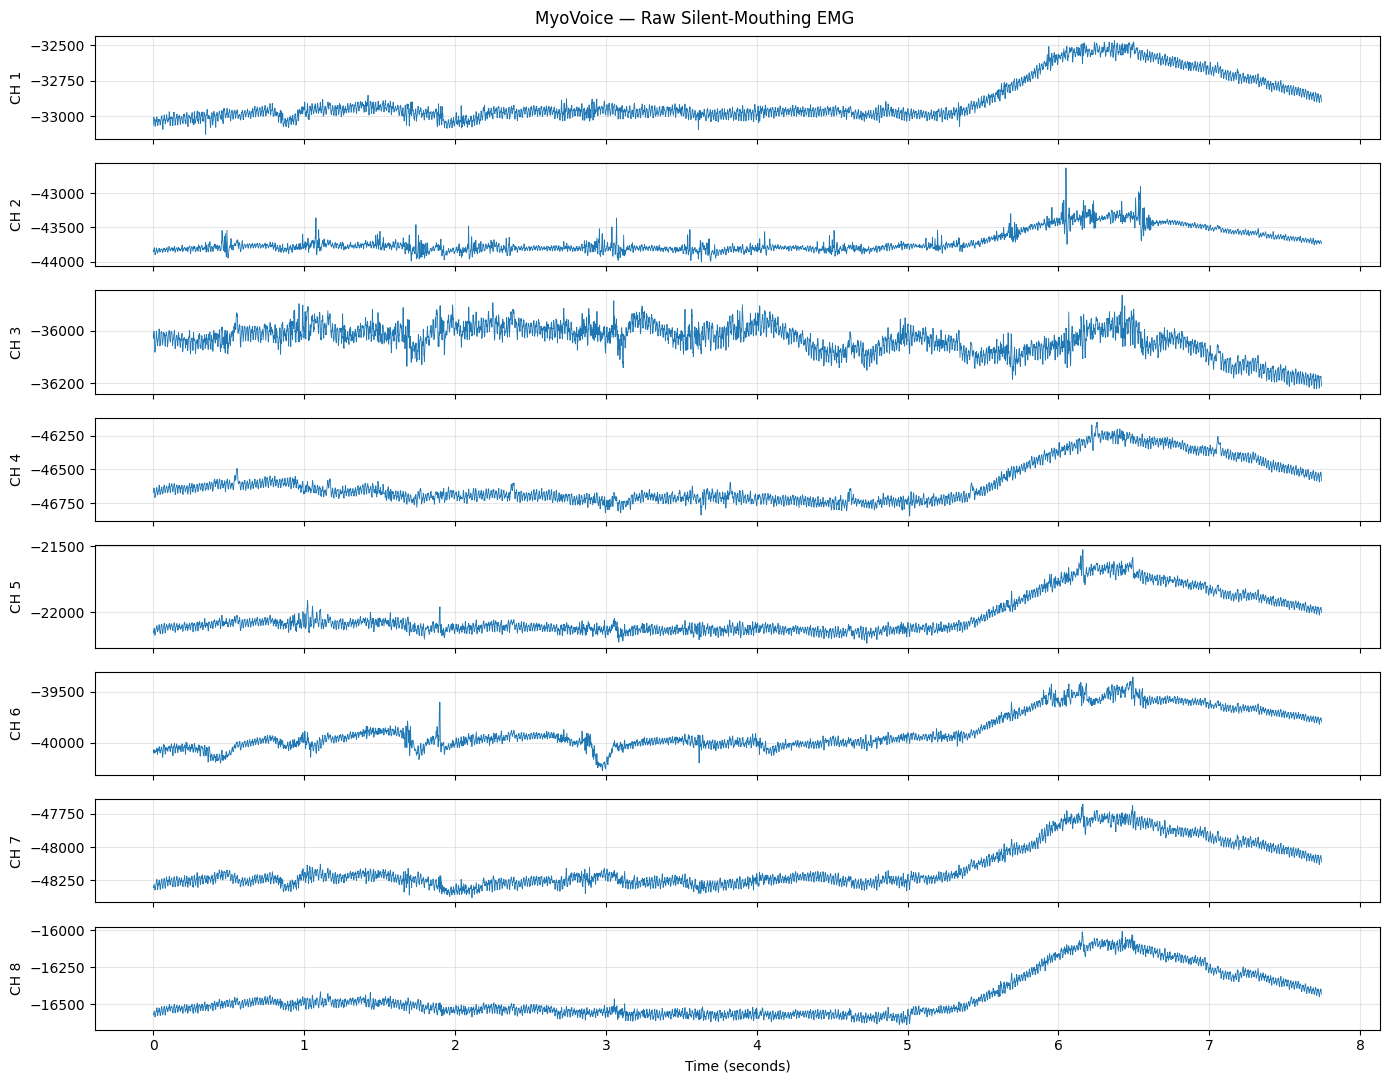

In [38]:

import matplotlib.pyplot as plt
import numpy as np

silent_time = np.arange(len(silent_emg)) / 1000

fig, axes = plt.subplots(8, 1, figsize=(14, 11), sharex=True)

for channel in range(8):
    axes[channel].plot(
        silent_time,
        silent_emg[:, channel],
        linewidth=0.6
    )
    axes[channel].set_ylabel(f"CH {channel + 1}")
    axes[channel].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("MyoVoice — Raw Silent-Mouthing EMG")
plt.tight_layout()
plt.show()


Original shape: (7746, 8)
Filtered shape: (7746, 8)
Filtered mean: -0.0278
Filtered standard deviation: 25.3326
Contains non-finite values: False


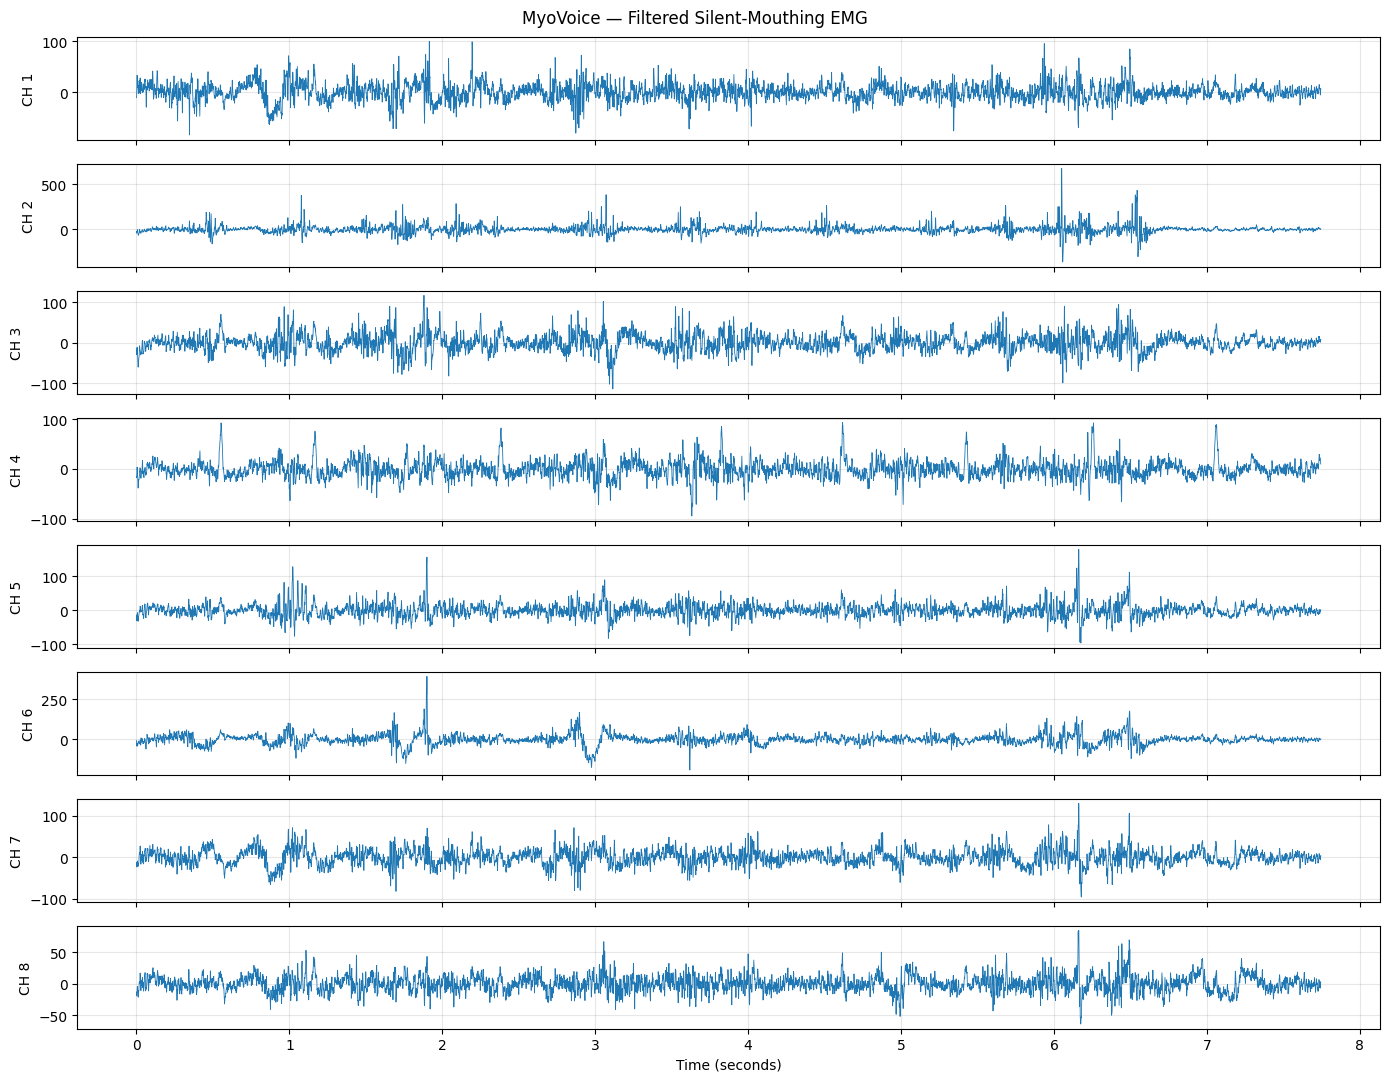

In [39]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, filtfilt

silent_filtered_emg = silent_emg.astype(np.float64).copy()
sampling_rate = 1000

# Remove 60 Hz electrical interference and its harmonics
for frequency in range(60, sampling_rate // 2, 60):
    b, a = iirnotch(frequency, Q=30, fs=sampling_rate)
    silent_filtered_emg = filtfilt(
        b, a, silent_filtered_emg, axis=0
    )

# Reduce slow baseline drift below 2 Hz
b, a = butter(3, 2, btype="highpass", fs=sampling_rate)
silent_filtered_emg = filtfilt(
    b, a, silent_filtered_emg, axis=0
)

print("Original shape:", silent_emg.shape)
print("Filtered shape:", silent_filtered_emg.shape)
print("Filtered mean:", round(float(silent_filtered_emg.mean()), 4))
print("Filtered standard deviation:", round(float(silent_filtered_emg.std()), 4))
print("Contains non-finite values:",
      not np.isfinite(silent_filtered_emg).all())

# Plot the filtered silent signal
fig, axes = plt.subplots(8, 1, figsize=(14, 11), sharex=True)
silent_time = np.arange(len(silent_filtered_emg)) / sampling_rate

for channel in range(8):
    axes[channel].plot(
        silent_time, silent_filtered_emg[:, channel],
        linewidth=0.6
    )
    axes[channel].set_ylabel(f"CH {channel + 1}")
    axes[channel].grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("MyoVoice — Filtered Silent-Mouthing EMG")
plt.tight_layout()
plt.show()


In [40]:

import numpy as np
import pandas as pd

sampling_rate = 1000
window_size = 200  # 200 ms
step_size = 50      # 50 ms between windows

silent_feature_rows = []
silent_feature_times = []

for start in range(
    0,
    len(silent_filtered_emg) - window_size + 1,
    step_size
):
    window = silent_filtered_emg[start:start + window_size, :]

    mav = np.mean(np.abs(window), axis=0)
    rms = np.sqrt(np.mean(window ** 2, axis=0))
    wl = np.sum(np.abs(np.diff(window, axis=0)), axis=0)

    silent_feature_rows.append(
        np.concatenate([mav, rms, wl])
    )
    silent_feature_times.append(
        (start + window_size / 2) / sampling_rate
    )

silent_feature_array = np.asarray(silent_feature_rows)

silent_feature_names = (
    [f"CH{i+1}_MAV" for i in range(8)]
    + [f"CH{i+1}_RMS" for i in range(8)]
    + [f"CH{i+1}_WL" for i in range(8)]
)

silent_features_df = pd.DataFrame(
    silent_feature_array,
    columns=silent_feature_names
)

print("Silent feature matrix shape:", silent_feature_array.shape)
print("Number of windows:", len(silent_feature_array))
print("Features per window:", silent_feature_array.shape[1])
print("Text label:", silent_info["text"])
print(
    "Contains non-finite values:",
    not np.isfinite(silent_feature_array).all()
)
print("\nFirst five windows:")
print(silent_features_df.head().round(3))


Silent feature matrix shape: (151, 24)
Number of windows: 151
Features per window: 24
Text label: The crowd far away on the left, towards Woking, seemed to grow, and I heard now a faint murmur from it.
Contains non-finite values: False

First five windows:
   CH1_MAV  CH2_MAV  CH3_MAV  CH4_MAV  CH5_MAV  CH6_MAV  CH7_MAV  CH8_MAV  \
0   10.743   14.414   11.686    9.202    9.802   15.630   10.996    8.342   
1   11.183   11.023    7.663    7.757    8.594   15.088   10.681    7.635   
2   10.767   11.241    7.737    7.704    8.181   17.174   11.376    7.428   
3   10.798   13.473    7.970    5.456    7.993   21.385   10.566    6.050   
4   14.293   17.055    8.867    5.755    8.635   25.399   11.693    6.316   

   CH1_RMS  CH2_RMS  ...  CH7_RMS  CH8_RMS    CH1_WL    CH2_WL    CH3_WL  \
0   14.045   19.315  ...   12.997   10.033  1214.737  1307.894   836.161   
1   14.676   14.118  ...   12.696    9.286  1271.425  1290.158   817.768   
2   14.987   14.574  ...   13.779    9.230  1440.235

In [41]:

from pathlib import Path

repo = Path("/content/MyoVoice/silent_speech_asr")

print("Repository exists:", repo.exists())

for name in [
    "README.md",
    "recognition_model.py",
    "architecture.py",
    "read_emg.py",
    "data_utils.py",
    "normalizers.pkl",
    "testset_largedev.json",
]:
    path = repo / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

if (repo / "README.md").exists():
    print("\n--- README: model and setup instructions ---")
    readme = (repo / "README.md").read_text()
    print(readme[:12000])


Repository exists: True
README.md: FOUND
recognition_model.py: MISSING
architecture.py: MISSING
read_emg.py: FOUND
data_utils.py: FOUND
normalizers.pkl: FOUND
testset_largedev.json: FOUND

--- README: model and setup instructions ---
# Voicing Silent Speech

This repository contains code for synthesizing speech audio from silently mouthed words captured with electromyography (EMG).
It is the official repository for the papers [Digital Voicing of Silent Speech](https://aclanthology.org/2020.emnlp-main.445.pdf) at EMNLP 2020, [An Improved Model for Voicing Silent Speech](https://aclanthology.org/2021.acl-short.23.pdf) at ACL 2021, and the dissertation [Voicing Silent Speech](https://www2.eecs.berkeley.edu/Pubs/TechRpts/2022/EECS-2022-68.pdf).
The current commit contains only the most recent model, but the versions from prior papers can be found in the commit history.
On an ASR-based open vocabulary evaluation, the latest model achieves a WER of approximately 36%.

## Data

The EMG and au

In [42]:

from pathlib import Path
from collections import Counter
import json

silent_dir = Path("/content/MyoVoice/emg_data/silent_parallel_data")

label_counts = Counter()
valid_samples = 0

for info_path in silent_dir.rglob("*_info.json"):
    try:
        info = json.loads(info_path.read_text())
        text = info.get("text", "").strip()
        sentence_index = info.get("sentence_index", -1)

        if not text or sentence_index == -1:
            continue

        stem = info_path.name.removesuffix("_info.json")
        emg_path = info_path.with_name(f"{stem}_emg.npy")

        if emg_path.exists():
            label_counts[text] += 1
            valid_samples += 1

    except (OSError, json.JSONDecodeError):
        continue

print("Valid labeled samples:", valid_samples)
print("Unique text labels:", len(label_counts))
print("\nMost frequent labels:")

for text, count in label_counts.most_common(15):
    print(f"{count:4d} | {text}")


Valid labeled samples: 1588
Unique text labels: 1583

Most frequent labels:
   6 | .
   1 | The crowd far away on the left, towards Woking, seemed to grow, and I heard now a faint murmur from it.
   1 | But it was scarcely a time for articulate conversation.
   1 | I had a momentary impulse to go back and help him that my fears overruled.
   1 | The sunset faded to twilight before anything further happened.
   1 | The description of their death, as it was seen by the crowd, tallies very closely with my own impressions: the three puffs of green smoke, the deep humming note, and the flashes of flame.
   1 | Flutter, flutter, went the flag, first to the right, then to the left.
   1 | The news of the massacre probably reached Chobham, Woking, and Ottershaw about the same time.
   1 | There were really, I should think, two or three hundred people elbowing and jostling one another, the one or two ladies there being by no means the least active.
   1 | I saw a lad trundling off the barrow of